In [22]:
import numpy as np
import pandas as pd
import random
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure

## Creating Board, postition tracker and dice

In [3]:
board = list(range(40))

In [4]:
counter = {tile: 0 for tile in board} #Dict counts the total number of landings per tile
position = 0 #resets position counter to zero

In [5]:
turn_dieroll = random.randint(1,6) + random.randint(1,6) #Random dieroll, two dice per turn

## Turn Movement

In [6]:
position = (position + turn_dieroll) % 40 #we treat 40 as the new 0, the "GO" tile.

In [7]:
counter[position] = counter[position] + 1 #counts the amounts of landings on a tile

## Reset Clause    

In [8]:
def reset():
    global counter, position
    counter = {tile: 0 for tile in board}
    position = 0

In [11]:
reset()

# Regular Momevent 

## Actual Movement

In [30]:
reset()
cycles = range(12000)     #Simulated amount of throws
i = 0
for i in cycles:
    dieroll = random.randint(1,6) + random.randint(1,6)
    position = (position + dieroll) % 40
    
    if position == 29:  #Cop is tile 30 (29 for python)
        position = 9    #if landed on Cop, player is sent to Jail in tile 10 (9 for Python)

    counter[position] = counter[position] + 1

sum(counter.values()) == len(cycles) #Boolean Sanity Check. Total values = total cycles/throws. Should be True.

True

## Plotting Results

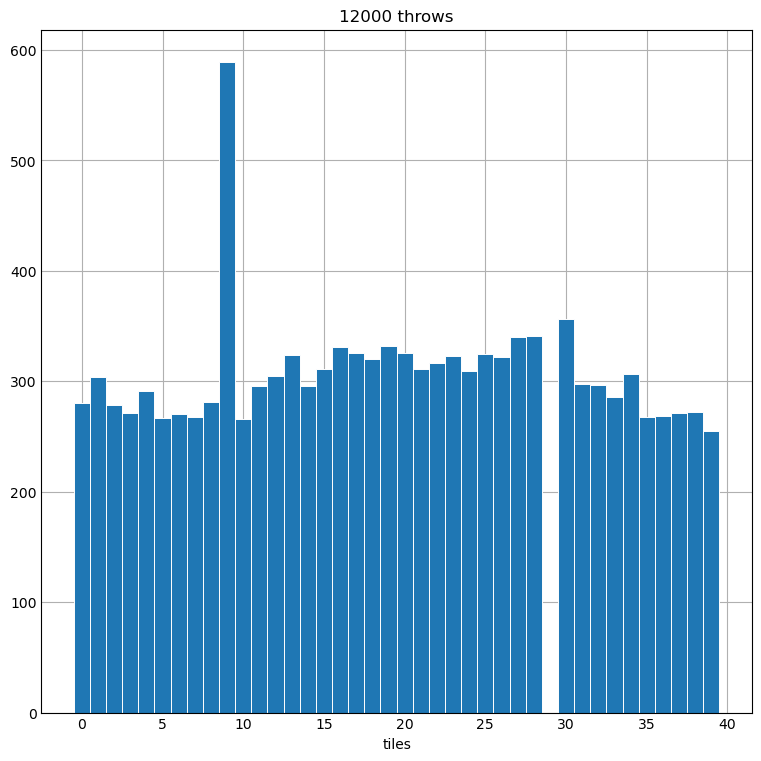

In [31]:
#creatting the unformatted chart
plt.style.use('_mpl-gallery')

x = counter.keys()
y = counter.values()


fig, ax = plt.subplots(layout="constrained")
ax.bar(x, y, width=1, edgecolor="white", linewidth=0.7)
ax.tick_params("x", rotation = 0)
ax.set_xlabel("tiles")
fig.set_size_inches(7.5, 7.5)

plt.title(f"{max(cycles)+1} throws") #Titles the chart with the number of throws. A bit gimmicky

plt.show()

On average, we should have around twice as many landings on the 10th tile since it converges both its natural "drop rate" and tile 29's.

Naturally, this creates a "hot zone" and a "cold zone" of the board which will make players land on tiles between 9 and 29 and thus skewing the graphs on the long term.